In [237]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

# Add the repo root when the kernel starts in an experiment folder
if Path.cwd().parent.name == 'experiments':
    sys.path.append(str(Path.cwd().parents[1]))

from experiments.rate_ctrl import RateControllerLin
from rate_model.eig_utils import random_W_real
from rate_model import RateModelWC

In [238]:
seed = np.random.randint(10000)
seed = 4979
np.random.seed(seed)
print(f"seed: {seed}")

#r0_target = 7, pop_ctrl = 2
# 3806
# 334
#r0_target = 3, pop_ctrl = 2
# 5778
#r0_target = 7, pop_ctrl = 1
# 4979

# Num. populations
N = 5

tau = 1   # time constant
rho = 0.9  # spectral radius   

# Baseline rate vector
r0 = np.linspace(2, 8, N).reshape(-1, 1)

# Model
model, h0, J = RateModelWC.from_steady_state(
    r0, tau=tau, rmax=10, gain_slope=0.5, gain_center=0, R=rho)

# Simulation params
T = 200
dt = 0.05
nsteps = int(T / dt)

# Add zero-mean noise around that operating point
sigma_h = 0.2
H = h0 + sigma_h * np.random.randn(N, nsteps) / np.sqrt(dt)

# Initial state
r_start = r0.copy()

seed: 4979


(-1.0, 2.0)

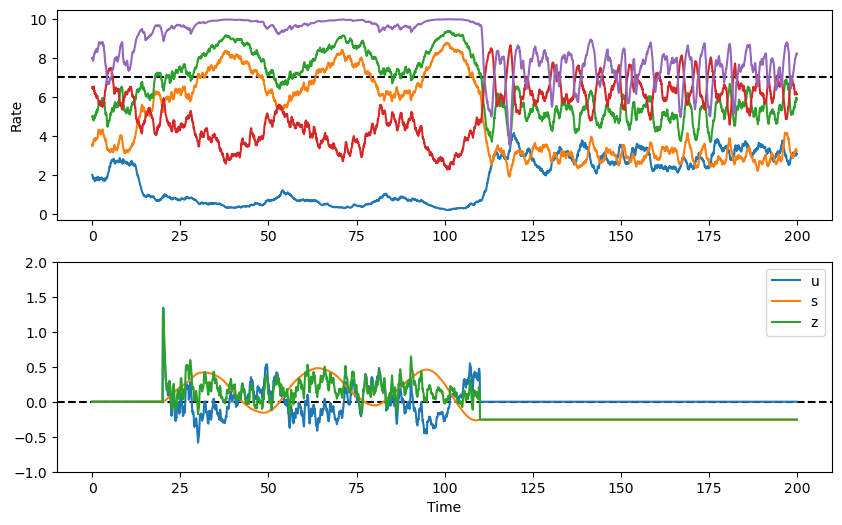

In [239]:
# Target rate
r0_target = 7
pop_ctrl = 1

# Rate controller
ctrl_par = {
    'taum': 1,
    'ks': 0.05,
    'tauu': 0.1,
    'ku': 1
}
ctrl = RateControllerLin(r0_target, **ctrl_par)
ctrl.begin(dt, nsteps, sim_res_type='full',
           activate_t=20, lock_t=110)

def rate_fb(r):
    r_ = np.asarray(r[[pop_ctrl]])
    z_ = ctrl.step(r_)['z'].item()
    z = np.zeros_like(r)
    z[pop_ctrl] = z_
    return z

# Run simulation
R = model.run(
    H, r_start, dt, nsteps,
    fb_proc=rate_fb
)
tt = R.coords['time']

# Plot result
plt.figure(figsize=(10, 6))

plt.subplot(2, 1, 1)
for n in range(N):
    if n == pop_ctrl:
        plt.axhline(r0_target, ls='--', color='k')
    plt.plot(tt, R.isel(pop=n))
#plt.xlabel('Time')
plt.ylabel('Rate')

plt.subplot(2, 1, 2)
plt.axhline(0, ls='--', color='k')
for k in ('u', 's', 'z'):
    vv = ctrl.state_xr[k].squeeze()
    plt.plot(tt[:-1], vv[:-1], label=k)
plt.legend()
plt.xlabel('Time')
plt.ylim(-1, 2)
